# Deep Learning
## Sequence Models, LSTM, GRU, Attention and Self-Attention

Beginner-friendly: **what, why, when, how, and where**.

### Learning roadmap
1. Sequential data and why order matters
2. Sequence models
3. RNN: the basic idea and limitations
4. Vanishing gradients and long-term dependencies
5. LSTM: gates and cell state
6. GRU: a simpler gated recurrent model
7. Compare RNN, LSTM and GRU
8. Attention: what problem does it solve?
9. Self-attention: queries, keys, values and the attention equation
10. A numerical self-attention example
11. Attention vs self-attention vs recurrent models
12. Applications, revision and self-test

> **Big picture:** RNNs, LSTMs and GRUs process sequences recurrently, step by step. Attention calculates how much different representations should contribute to a query. Self-attention lets positions in the same sequence relate to one another. Standard Transformers are built around attention and feed-forward layers rather than recurrent processing.

## 0. Setup

We use NumPy for calculations, Matplotlib for a simple plot, and PyTorch for a tiny LSTM/GRU example. The PyTorch example demonstrates shapes and usage; it does not train a useful model.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
print("NumPy:", np.__version__)

NumPy: 1.26.4


## 1. What is sequential data?

**Sequential data** is data in which order carries meaning.

Examples:
- **Text:** “The dog chased the cat” differs from “The cat chased the dog.”
- **Speech/audio:** Sounds unfold over time.
- **Time series:** Temperature recorded hour by hour.
- **Video:** Frames appear in temporal order.
- **Sensor data:** Motion, heart rate, or machine vibration measured over time.

If shuffling the elements destroys useful meaning, sequence-aware methods may be appropriate.

## 2. What is a sequence model?

A **sequence model** learns patterns in ordered data. Depending on the task, it may use earlier elements to understand or predict later ones.

### What, why, when, where
- **What:** A model designed for ordered inputs or outputs.
- **Why:** Context and order can change meaning.
- **When:** Text, speech, sensor streams, time series, video and other ordered data.
- **Where:** Translation, speech recognition, forecasting, language modeling and sequence labeling.

Examples: predict the next word, forecast the next sensor reading, or label each word in a sentence.

## 3. RNN: the basic recurrent model

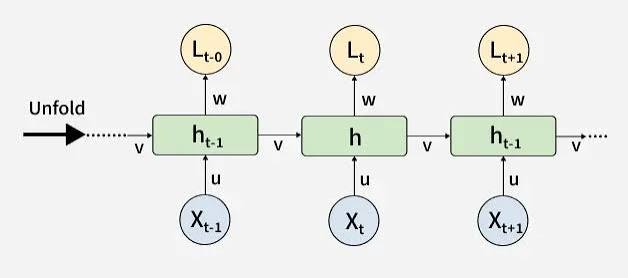

RNN stands for **Recurrent Neural Network**. It processes a sequence step by step and carries a hidden state from one step to the next.

Think of the hidden state as a compact running summary of what the network has seen so far.

At time step t:

`h_t = φ(W_x x_t + W_h h_(t-1) + b)`

- `x_t`: current input
- `h_(t-1)`: previous hidden state
- `h_t`: updated hidden state
- `W_x`, `W_h`: learned weight matrices
- `b`: bias
- `φ`: activation, often tanh in a basic RNN

The same learned weights are reused at each time step. This is **parameter sharing**.

### How to picture an RNN

For “I love deep learning,” the RNN processes one word at a time. Each word updates the hidden state using the current word and previous state.

The hidden state is not a perfect record of every word. It is a fixed-size representation, which can make very long-range dependencies difficult to learn.

## 4. Why did we need LSTM and GRU?

Basic RNNs can struggle to learn relationships between elements far apart in a sequence. During backpropagation through many time steps, gradients may become extremely small (**vanishing gradients**) or very large (**exploding gradients**).

If a useful clue appears early in a long sequence, a basic RNN may struggle to preserve its influence until much later.

LSTM and GRU use **gates** to control how information is kept, updated, or discarded. They help with long-term dependencies, though they do not eliminate every training challenge.

## 5. LSTM: Long Short-Term Memory

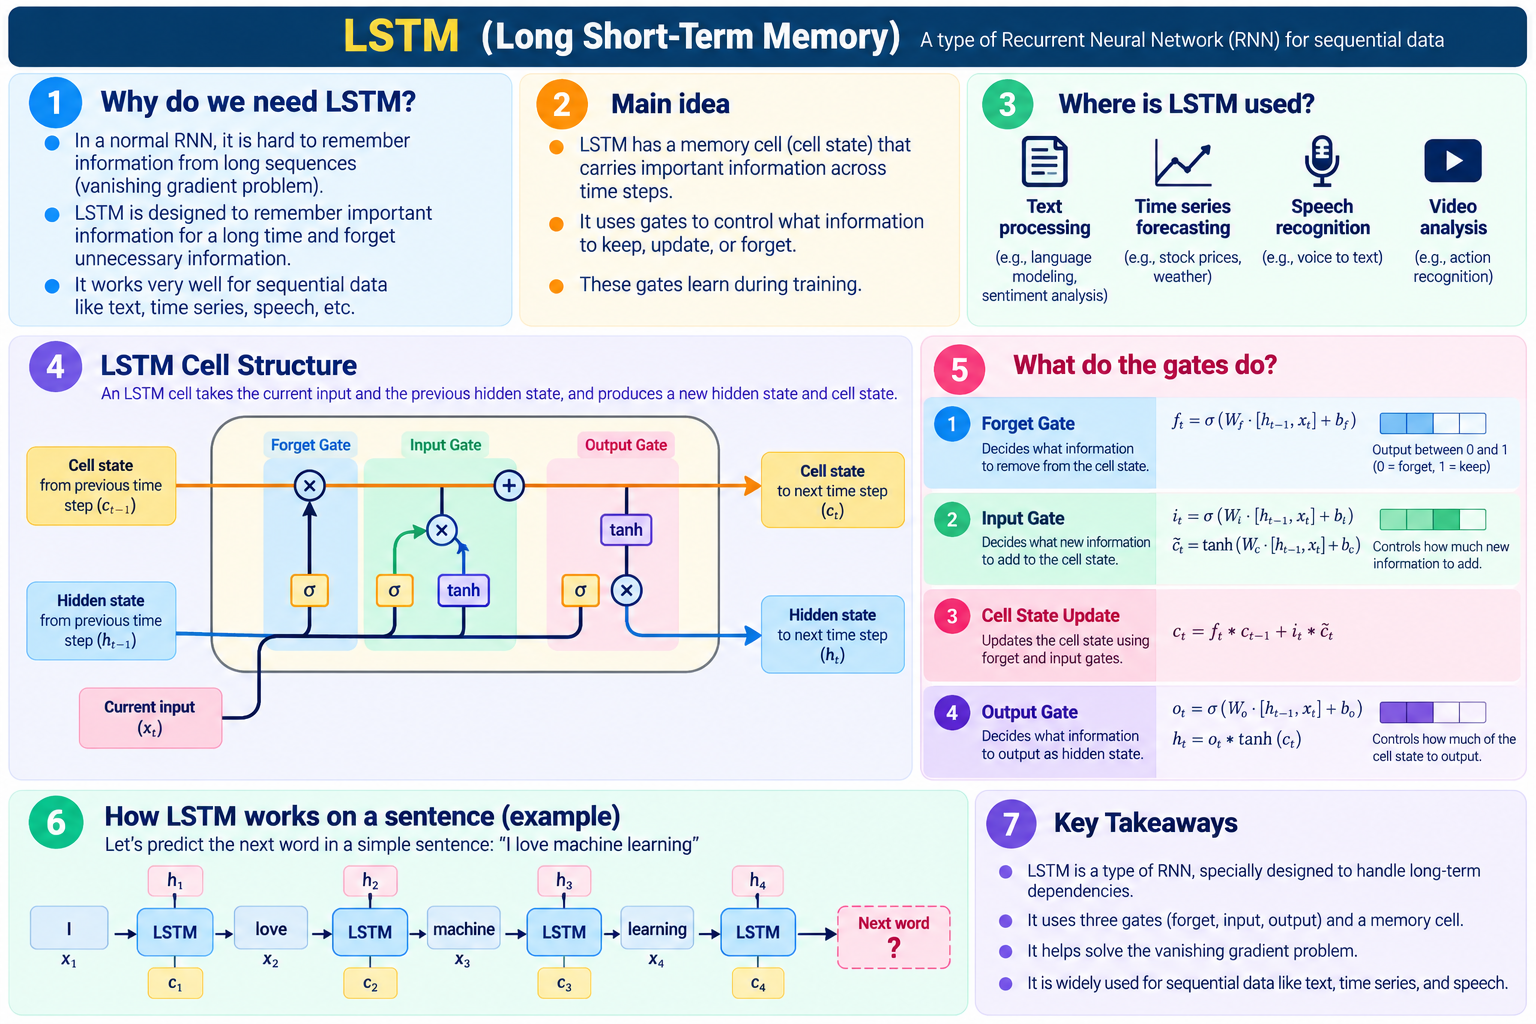

An **LSTM** is a recurrent neural network designed to manage information over longer sequences.

Its key idea is a **cell state**, a memory pathway, plus gates that control information flow.

Three main gates:
1. **Forget gate:** How much previous cell-state information to retain.
2. **Input gate:** How much new information to write.
3. **Output gate:** How much cell-state information contributes to the hidden state.

Intuition: while reading a chapter, discard irrelevant details, retain important facts, and use them when answering a question. This is an analogy; LSTM gates are learned mathematical operations.

### LSTM equations (conceptual form)

`f_t = sigmoid(W_f [h_(t-1), x_t] + b_f)`

`i_t = sigmoid(W_i [h_(t-1), x_t] + b_i)`

`c_candidate = tanh(W_c [h_(t-1), x_t] + b_c)`

`c_t = f_t ⊙ c_(t-1) + i_t ⊙ c_candidate`

`o_t = sigmoid(W_o [h_(t-1), x_t] + b_o)`

`h_t = o_t ⊙ tanh(c_t)`

- `f_t`: forget gate; `i_t`: input gate; `o_t`: output gate
- `c_t`: updated cell state; `h_t`: hidden state
- `⊙`: element-wise multiplication
- `[h_(t-1), x_t]`: concatenated previous hidden state and current input

For a first pass, remember: **forget, write, expose**.

## 6. GRU: Gated Recurrent Unit

A **GRU** is another gated recurrent model. It aims to provide some benefits of LSTM with a simpler structure.

- **Update gate:** Controls how much previous state is retained versus replaced with new information.
- **Reset gate:** Controls how much previous state is used to form a candidate state.

A typical GRU has no separate cell state; it uses a hidden state.

### Why use a GRU?
- Fewer gate components than a standard LSTM.
- Can be computationally cheaper in some settings.
- May perform comparably to LSTM; the better choice depends on the task and data.

**Memory aid:** LSTM = forget/input/output gates + separate cell state. GRU = update/reset gates + one main hidden state.

## 7. RNN vs LSTM vs GRU

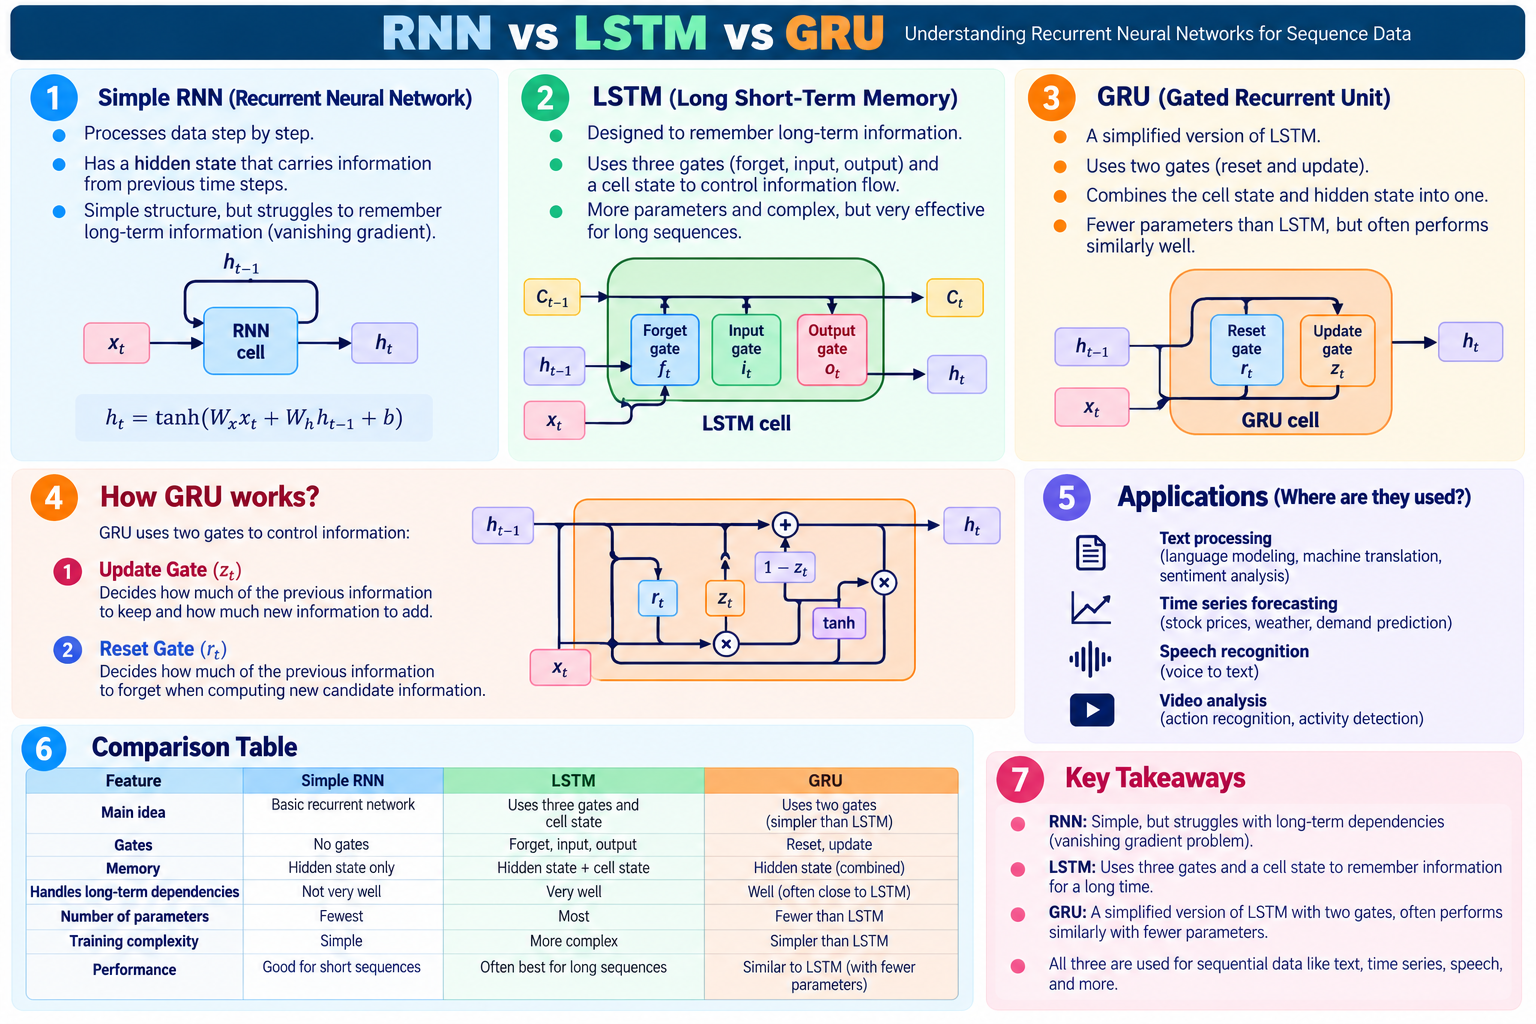


| Feature | Basic RNN | LSTM | GRU |
|---|---|---|---|
| Main idea | Recurrent hidden state | Gated memory with cell state | Gated hidden state |
| Gates | No LSTM-style gates | Forget, input, output | Update, reset |
| Long dependencies | Often difficult | Designed to help | Designed to help |
| Complexity | Simplest | Usually most complex of these three | Usually simpler than LSTM |
| Speed | Depends on task and setup | Can be slower | Can be faster, but not always |

There is no universal winner. Compare using validation data, suitable metrics and task constraints.

## 8. Tiny RNN-family example in PyTorch

PyTorch batch-first sequence input has shape `(batch_size, sequence_length, input_features)`. This example sends random data through LSTM and GRU to demonstrate tensor shapes only.

In [2]:
try:
    import torch
    import torch.nn as nn

    batch_size, sequence_length, input_features, hidden_size = 4, 6, 3, 8
    x = torch.randn(batch_size, sequence_length, input_features)

    lstm = nn.LSTM(input_size=input_features, hidden_size=hidden_size, batch_first=True)
    gru = nn.GRU(input_size=input_features, hidden_size=hidden_size, batch_first=True)

    lstm_output, (lstm_h, lstm_c) = lstm(x)
    gru_output, gru_h = gru(x)

    print("Input:", x.shape)
    print("LSTM sequence output:", lstm_output.shape)
    print("LSTM final hidden state:", lstm_h.shape)
    print("LSTM final cell state:", lstm_c.shape)
    print("GRU sequence output:", gru_output.shape)
    print("GRU final hidden state:", gru_h.shape)
except ImportError:
    print("PyTorch is not installed. Install torch to run this section.")

Input: torch.Size([4, 6, 3])
LSTM sequence output: torch.Size([4, 6, 8])
LSTM final hidden state: torch.Size([1, 4, 8])
LSTM final cell state: torch.Size([1, 4, 8])
GRU sequence output: torch.Size([4, 6, 8])
GRU final hidden state: torch.Size([1, 4, 8])


### Understand the shapes
- Input `(4, 6, 3)`: 4 sequences, 6 time steps, 3 features per step.
- Sequence output `(4, 6, 8)`: an 8-dimensional representation for each time step.
- Final hidden state `(1, 4, 8)`: one recurrent layer and each batch item.
- LSTM also returns a cell state; standard GRU does not return a separate cell state.

The leading `1` is the number of recurrent layers/directions in this example.

## 9. What is attention, and why was it introduced?

When translating a sentence, the model generating a target word may need to focus on a particular source word or phrase.

A single final RNN state can become a bottleneck because it must summarize a long input. **Attention** gives a model a way to weight relevant representations instead of relying only on one compressed summary.

### What, why, when, where
- **What:** A mechanism that computes weights indicating how relevant representations are to a query.
- **Why:** Some input elements matter more than others for a particular prediction.
- **When:** Translation, summarization, question answering, text generation, vision and multimodal tasks.
- **Where:** Encoder-decoder models, Transformers, vision models and many other neural architectures.

Example: in “The animal didn't cross the street because it was tired,” context helps connect “it” to the relevant earlier noun.

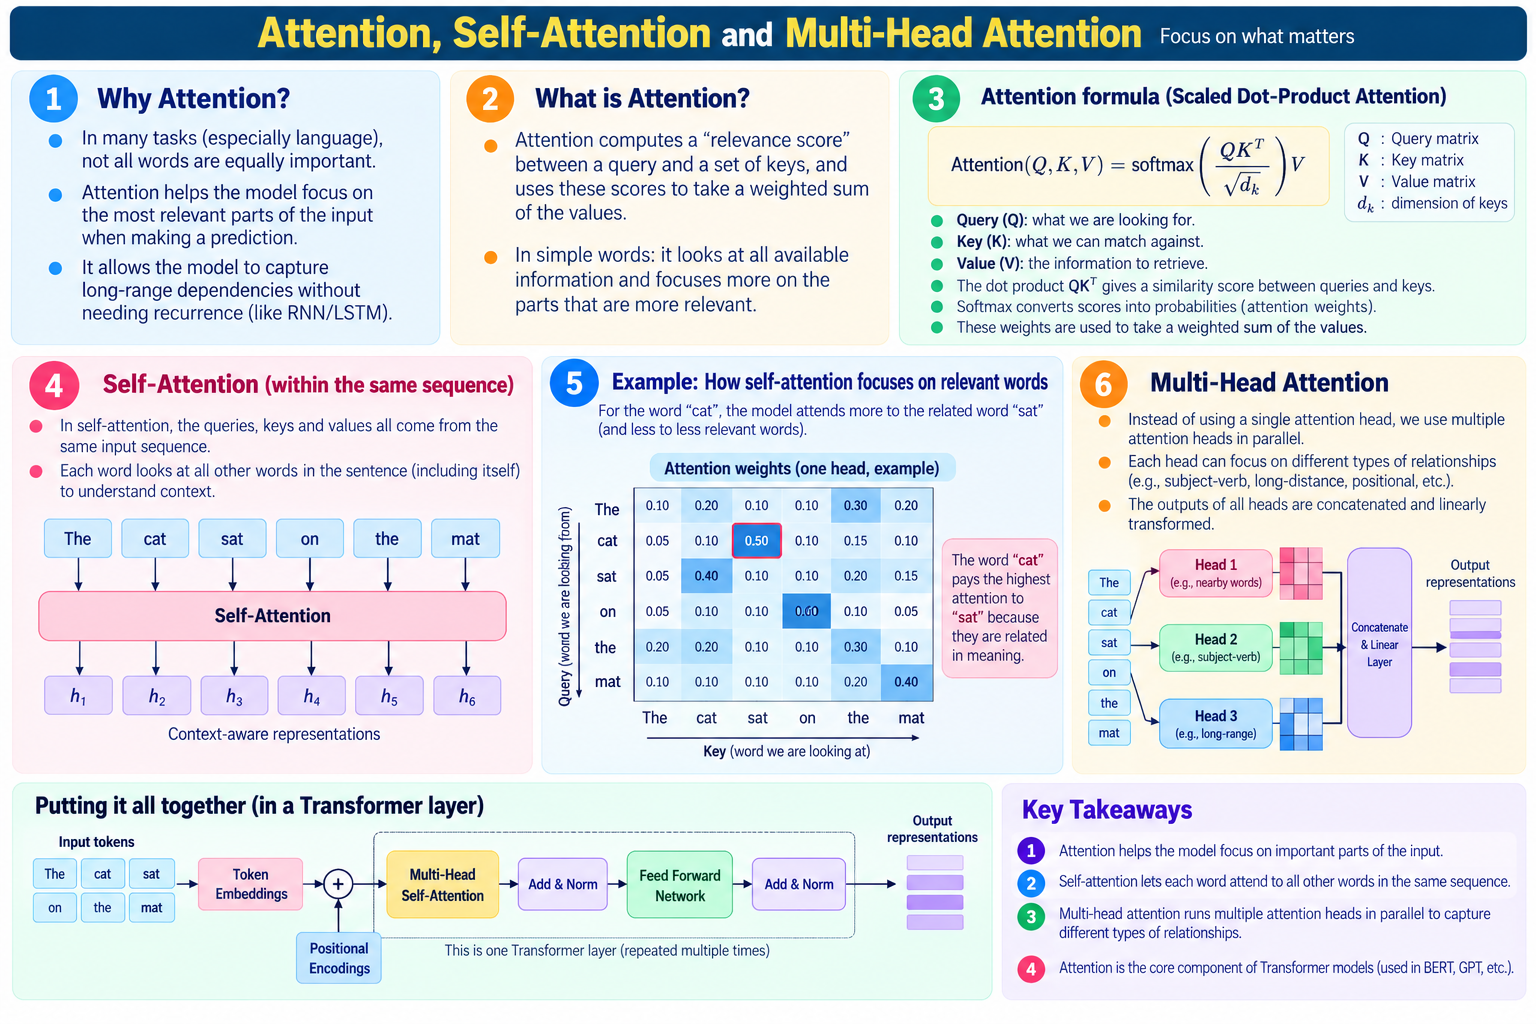

## 10. Attention vs self-attention

### Attention (general)
A query uses a set of key-value representations. In classic encoder-decoder attention, the query may come from the decoder, while keys and values come from the encoder.

### Self-attention
Queries, keys and values are produced from the **same sequence of input representations**. Each position can assign different weights to other positions in that sequence.

Example: in “The bank was beside the river,” the representation of “bank” can use context such as “river” to help represent its meaning.

Self-attention does not automatically know the correct meaning; it learns contextual relationships from data.

## 11. Self-attention: query, key and value

The names are inspired by information retrieval:
- **Query (Q):** What this position is looking for.
- **Key (K):** What each position offers for matching.
- **Value (V):** The information that can be combined if a position is relevant.

For input matrix `X`, learned matrices produce:

`Q = X W_Q`, `K = X W_K`, `V = X W_V`

Scaled dot-product attention:

`Attention(Q,K,V) = softmax((Q Kᵀ) / sqrt(d_k)) V`

Steps:
1. Calculate similarity scores between queries and keys using `Q Kᵀ`.
2. Divide by `sqrt(d_k)` to control score scale.
3. Apply softmax so each row becomes weights summing to 1.
4. Use the weights to combine value vectors.

The output at each position is a context-aware mixture of value vectors.

## 12. Numerical self-attention example

To focus on the core idea, use tiny, already-projected query, key and value vectors. This omits learned projections and uses a small dimension so every step is visible.

In [ ]:
import numpy as np

Q = np.array([[1.0, 0.0],
              [0.0, 1.0],
              [1.0, 1.0]])
K = np.array([[1.0, 0.0],
              [0.0, 1.0],
              [1.0, 1.0]])
V = np.array([[10.0, 0.0],
              [0.0, 10.0],
              [5.0, 5.0]])

def softmax(x, axis=-1):
    x = x - np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)

d_k = K.shape[-1]
scores = Q @ K.T
scaled_scores = scores / np.sqrt(d_k)
weights = softmax(scaled_scores, axis=-1)
contextual_output = weights @ V

print("Raw scores:\n", np.round(scores, 3))
print("\nScaled scores:\n", np.round(scaled_scores, 3))
print("\nAttention weights:\n", np.round(weights, 3))
print("\nContextual output:\n", np.round(contextual_output, 3))
print("\nRow sums:", np.round(weights.sum(axis=-1), 3))

### Interpret the output
- Each row represents one query token.
- Each column in the attention-weight matrix represents one key token.
- A larger weight means that token contributes more to the value mixture for that query.
- The output for each token is contextualized by information from the sequence.

In a real Transformer, Q, K and V are learned projections of token representations, and multiple heads can learn different relationship patterns.

## 13. Why divide by the square root of the key dimension?

Dot products can grow in magnitude as the vector dimension grows. Large scores can make softmax distributions very peaked, which may lead to small gradients in less-attended positions.

Dividing by `sqrt(d_k)` helps control the score scale. This is **scaled dot-product attention**.

## 14. Causal masks and padding masks

- **Causal mask:** Prevents a position from attending to future positions. This matters in next-token generation, so the model cannot peek at the answer.
- **Padding mask:** Prevents padding tokens added to align batch lengths from being treated as meaningful content.

Not all attention uses a causal mask. An encoder processing a complete input sentence can often attend to tokens on both sides.

## 15. Multi-head attention

Rather than calculate attention once, a Transformer commonly uses multiple heads. Each head has its own learned projections and can learn different relationships.

The head outputs are combined and projected to form the layer output.

**Memory aid:** Single-head attention = one attention calculation. Multi-head attention = several learned attention calculations in parallel.

## 16. Where are these models used?

| Task/data | Possible model family | Why it may fit |
|---|---|---|
| Short sensor sequence | RNN, GRU, 1D CNN | Processes ordered measurements |
| Long sequence forecasting | LSTM, GRU, Transformer, statistical baselines | Models temporal dependencies; compare alternatives |
| Speech sequence | CNN front-end, RNN-family model, Transformer | Learns patterns across time |
| Text generation | Transformer with causal self-attention | Uses prior context to predict next tokens |
| Translation | Encoder-decoder attention or Transformer | Relates source and target context |
| Video/action recognition | CNN + temporal model, video Transformer | Captures visual content and temporal relationships |
| Document understanding | Transformer with self-attention | Builds contextual token representations |

There is no single model best for every sequence. Consider sequence length, dataset size, latency, compute and validation results.

## 17. Common misunderstandings

1. **“LSTM and GRU are attention mechanisms.”** No; they are gated recurrent architectures.
2. **“Attention and self-attention are exactly the same.”** Self-attention is a form of attention where Q, K and V come from the same sequence.
3. **“Attention always picks one word.”** It usually distributes weights across positions.
4. **“A Transformer is just an LSTM with attention.”** No; standard Transformers use attention and feed-forward layers without recurrent processing in their main architecture.
5. **“LSTM always beats GRU.”** No; compare them on the actual task.
6. **“Attention weights prove causal reasoning.”** No; weights show information mixing, not a complete explanation of reasoning.
7. **“Self-attention automatically knows word order.”** Attention alone does not inherently encode sequence order. Transformers need positional information or another way to represent positions.

## 18. Quick revision sheet

- **Sequential data:** Ordered data where order carries meaning.
- **Sequence model:** Learns patterns across ordered inputs/outputs.
- **RNN:** Reuses hidden state from one time step to the next.
- **Hidden state:** Learned representation summarizing information at a step.
- **Vanishing gradient:** Gradients become very small during training.
- **LSTM:** Recurrent model with cell state and forget/input/output gates.
- **GRU:** Recurrent model with update/reset gates and no separate cell state in its standard form.
- **Attention:** Weights representations relevant to a query.
- **Self-attention:** Each position attends to representations from the same sequence.
- **Query:** Represents what a position seeks.
- **Key:** Used to compute relevance scores.
- **Value:** Information combined using attention weights.
- **Softmax:** Converts scores into normalized weights.
- **Scaled dot-product attention:** `softmax(Q Kᵀ / sqrt(d_k)) V`.
- **Causal mask:** Blocks access to future positions.
- **Multi-head attention:** Runs several attention operations in parallel.
- **Transformer:** Uses attention and feed-forward blocks, typically with positional information.

## 19. Self-test questions

Try to answer without looking at the notes.

1. What makes data sequential?
2. Why can order change the meaning of a sentence?
3. What is the hidden state in an RNN?
4. Why can a basic RNN struggle with long dependencies?
5. What are the three main gates in an LSTM?
6. What are the two main gates in a GRU?
7. State one structural difference between LSTM and GRU.
8. What problem does attention help address?
9. Explain the difference between encoder-decoder attention and self-attention.
10. What do query, key and value represent?
11. Why are attention scores scaled by `sqrt(d_k)`?
12. What does softmax do to attention scores?
13. What is the purpose of a causal mask?
14. Why do Transformers need positional information?
15. Give two tasks for which sequence or attention models may be suitable.

### Suggested study method
1. Study sections 1–4 first.
2. Explain RNN → LSTM → GRU in your own words.
3. Then study attention and self-attention separately.
4. Run the code examples and inspect shapes and attention weights.
5. Answer the self-test without notes.